# N-Body Gravitational Dynamics with Verlet Integration

A direct-summation N-body gravity simulator using position Verlet. I test it on a two-body orbit (energy conservation and time reversibility), integrate the Solar System from JPL Horizons initial conditions, and measure Mercury's perihelion precession under a Jupiter perturbation and a GR-style correction.

**Units:** lengths in AU, masses in solar masses, time in units of 1 year / 2π, so G = 1 and Earth's orbital period is 2π.

| variable | description |
|----------|-------------|
| `N` | number of particles |
| `M` | total mass of all particles |
| `G` | gravitational constant (1 in computational units) |
| `mass[i]` | mass of particle i |
| `position[i, j]` | coordinate j of particle i |
| `positions[i, j, k]` | coordinate j of particle i at time step k |

*Credit: `accel_grav`, `first_step`, `verlet_step` and `grav_sim` are adapted from PHYS 440/740 course materials (Prof. Barranco, San Francisco State University, Spring 2026).*

## 1. Energy conservation in a two-body orbit

A Sun and an Earth-mass planet on an elliptical orbit (initial speed set to 80% of the circular value). Verlet doesn't track velocity, so I recover it from the saved positions with second-order finite differences, then compute kinetic, potential, and total energy. I compare the energy error ΔE = E(t) − E(0) across six step sizes, from 45 to 1440 steps per orbit.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# ============================================================
# Functions defined
# ============================================================

def accel_grav(mass, position):
    N = mass.shape[0]
    accel_grav = np.zeros([N,3])
    for i in range(N-1):
        for j in range(i+1,N):
            displacement = position[j,:]-position[i,:]
            distance_cubed = (displacement[0]**2+displacement[1]**2+displacement[2]**2)**1.5
            displacement = displacement/distance_cubed
            accel_grav[i,:] += mass[j]*displacement
            accel_grav[j,:] -= mass[i]*displacement
    return accel_grav

def first_step(position,velocity,acceleration,dt):
    return position+dt*velocity+0.5*(dt**2)*acceleration

def verlet_step(position,position_old,acceleration,dt):
    return 2.0*position-position_old+(dt**2)*acceleration

def grav_sim(mass,initial_position,initial_velocity,dt,num_steps):
    positions=np.zeros([mass.size,3,num_steps+1])
    positions[:,:,0]=initial_position
    acceleration=accel_grav(mass,initial_position)
    position=first_step(initial_position,initial_velocity,acceleration,dt)
    position_old = initial_position
    positions[:,:,1]=position
    for t in range(2,num_steps+1):
        acceleration=accel_grav(mass,position)
        position_new=verlet_step(position,position_old,acceleration,dt)
        position_old=position
        position=position_new
        positions[:,:,t]=position
    return positions

def compute_velocities(positions, dt):
    
    num_steps = positions.shape[2] - 1
    velocities = positions * 0
    # 2nd-order forward difference at t=0
    velocities[:,:,0] = -3.0*positions[:,:,0] + 4.0*positions[:,:,1] - positions[:,:,2]
    # 2nd-order central difference for interior
    velocities[:,:,1:num_steps] = positions[:,:,2:num_steps+1] - positions[:,:,0:num_steps-1]
    # 2nd-order backward difference at t=end
    velocities[:,:,num_steps] = 3.0*positions[:,:,num_steps] - 4.0*positions[:,:,num_steps-1] + positions[:,:,num_steps-2]
    return velocities / (2.0 * dt)

# ============================================================
# ENERGY FUNCTIONS
# ============================================================

def compute_kinetic_energy(mass, velocities):
    """
    Total kinetic energy at each time step.
    KE = sum_i (1/2) m_i |v_i|^2
    """
    v_squared = np.sum(velocities**2, axis=1)          # (N, num_steps+1)
    KE = 0.5 * np.sum(mass[:, np.newaxis] * v_squared, axis=0)  # (num_steps+1,)
    return KE

def compute_potential_energy(mass, positions, G=1.0):
    """
    Total gravitational potential energy at each time step.
    PE = -G * sum_{i<j} m_i m_j / r_ij
    """
    N = mass.shape[0]
    num_times = positions.shape[2]
    PE = np.zeros(num_times)
    for i in range(N-1):
        for j in range(i+1, N):
            dr = positions[j,:,:] - positions[i,:,:]   # (3, num_times)
            r = np.sqrt(np.sum(dr**2, axis=0))          # (num_times,)
            PE -= G * mass[i] * mass[j] / r
    return PE

# ============================================================
# SET UP ELLIPTICAL ORBIT
# ============================================================

G = 1.0
N = 2
mass = np.array([1.00, 3.0e-6])  # Sun + Earth-mass planet

T = 2.0 * np.pi               # orbital period = 1 year (in computational time)
w = 2.0 * np.pi / T           # angular frequency = 1
M = np.sum(mass)
a = (G * M / w**2)**(1.0/3.0) # semi-major axis from Kepler's 3rd law

# Place on x-axis with COM at origin
initial_position = np.zeros([N, 3])
initial_position[0,:] = np.array([-a*mass[1]/M, 0, 0])
initial_position[1,:] = np.array([+a*mass[0]/M, 0, 0])

# Elliptical orbit: reduce circular velocity by factor 0.8
v_factor = 0.8
initial_velocity = np.zeros([N, 3])
initial_velocity[0,:] = np.array([0, initial_position[0,0], 0]) * w * v_factor
initial_velocity[1,:] = np.array([0, initial_position[1,0], 0]) * w * v_factor

# ============================================================
# RUN FOR 6 DIFFERENT TIME STEPS
# ============================================================

tot_time = 6.0 * 2.0 * np.pi    # 6 orbital periods
steps_per_orbit_list = [45, 90, 180, 360, 720, 1440]

results = {}

for spo in steps_per_orbit_list:
    dt = 2.0 * np.pi / spo
    num_steps = int(np.ceil(tot_time / dt))

    positions = grav_sim(mass, initial_position, initial_velocity, G*dt, num_steps)
    velocities = compute_velocities(positions, G*dt)

    KE = compute_kinetic_energy(mass, velocities)
    PE = compute_potential_energy(mass, positions, G)
    E_total = KE + PE

    t_array = np.linspace(0, tot_time, num_steps+1) / (2*np.pi)  # convert to years

    results[spo] = {
        'dt': dt, 'positions': positions, 'velocities': velocities,
        'KE': KE, 'PE': PE, 'E': E_total, 't': t_array, 'num_steps': num_steps
    }

    print(f"steps/orbit={spo:5d}  dt={dt:.6f}  max|dE|={np.max(np.abs(E_total[1:-1]-E_total[0])):.2e}")



steps/orbit=   45  dt=0.139626  max|dE|=9.22e-08
steps/orbit=   90  dt=0.069813  max|dE|=2.51e-08
steps/orbit=  180  dt=0.034907  max|dE|=6.42e-09
steps/orbit=  360  dt=0.017453  max|dE|=1.61e-09
steps/orbit=  720  dt=0.008727  max|dE|=4.04e-10
steps/orbit= 1440  dt=0.004363  max|dE|=1.01e-10


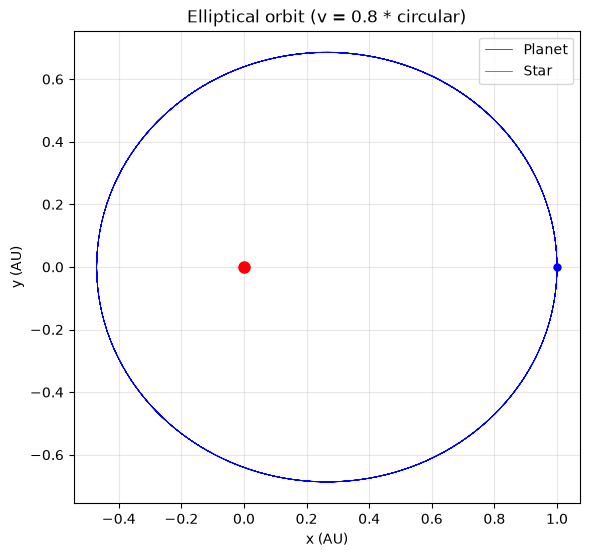

In [2]:
# ============================================================
# FIGURE 1: ORBIT PLOT
# ============================================================
r = results[720]
fig, ax = plt.subplots(figsize=(6, 6))
ax.plot(r['positions'][1,0,:], r['positions'][1,1,:], 'b-', lw=0.5, label='Planet')
ax.plot(r['positions'][0,0,:], r['positions'][0,1,:], 'r-', lw=0.5, label='Star')
ax.plot(r['positions'][1,0,0], r['positions'][1,1,0], 'bo', ms=5)
ax.plot(r['positions'][0,0,0], r['positions'][0,1,0], 'ro', ms=8)
ax.set_xlabel('x (AU)')
ax.set_ylabel('y (AU)')
ax.set_title('Elliptical orbit (v = 0.8 * circular)')
ax.set_aspect('equal')
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('fig_1a_orbit.png', dpi=150, bbox_inches='tight')
plt.show()


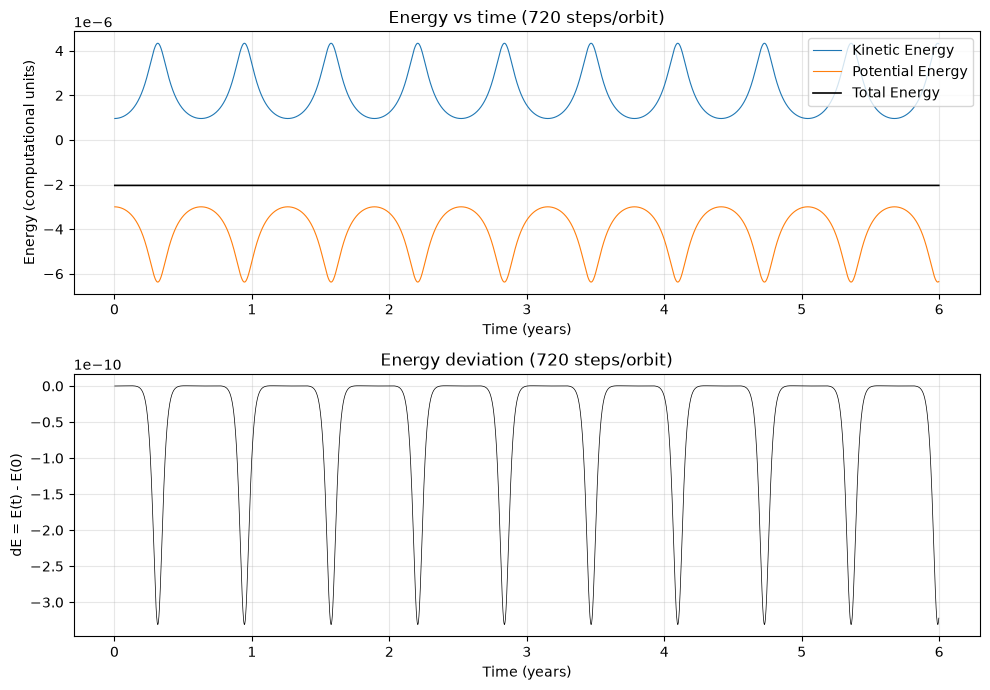

In [3]:

# ============================================================
# FIGURE 2: KE, PE, TOTAL ENERGY vs TIME (representative dt)
# ============================================================
r = results[720]
sl = slice(2, -2)

fig, axes = plt.subplots(2, 1, figsize=(10, 7))

axes[0].plot(r['t'][sl], r['KE'][sl], label='Kinetic Energy', lw=0.8)
axes[0].plot(r['t'][sl], r['PE'][sl], label='Potential Energy', lw=0.8)
axes[0].plot(r['t'][sl], r['E'][sl], 'k-', label='Total Energy', lw=1.2)
axes[0].set_xlabel('Time (years)')
axes[0].set_ylabel('Energy (computational units)')
axes[0].set_title('Energy vs time (720 steps/orbit)')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

axes[1].plot(r['t'][sl], r['E'][sl] - r['E'][2], 'k-', lw=0.5)
axes[1].set_xlabel('Time (years)')
axes[1].set_ylabel('dE = E(t) - E(0)')
axes[1].set_title('Energy deviation (720 steps/orbit)')
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('fig_1a_energy.png', dpi=150, bbox_inches='tight')
plt.show()



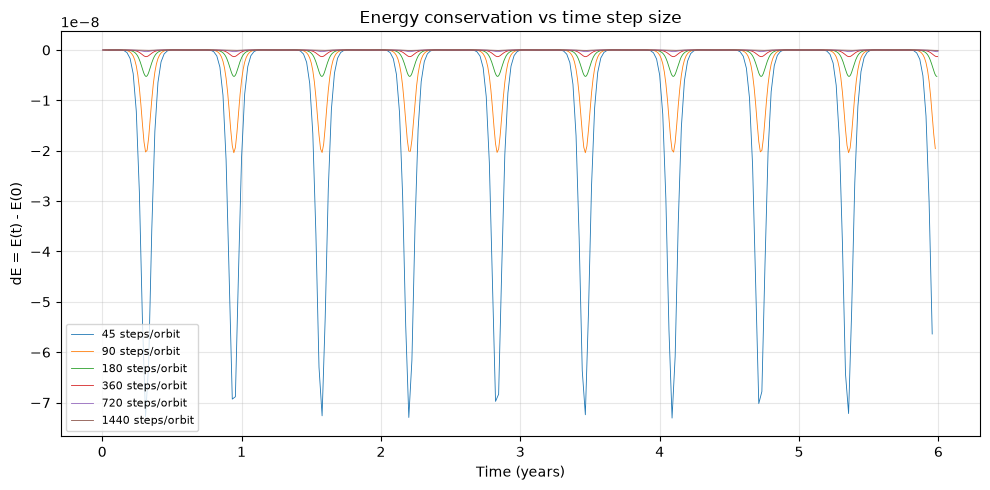

In [4]:
# ============================================================
# FIGURE 3: dE vs TIME FOR ALL 6 TIME STEPS
# ============================================================
fig, ax = plt.subplots(figsize=(10, 5))

for spo in steps_per_orbit_list:
    r = results[spo]
    sl = slice(2, -2)
    dE = r['E'][sl] - r['E'][2]
    ax.plot(r['t'][sl], dE, lw=0.6, label=f'{spo} steps/orbit')

ax.set_xlabel('Time (years)')
ax.set_ylabel('dE = E(t) - E(0)')
ax.set_title('Energy conservation vs time step size')
ax.legend(fontsize=8)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('fig_1a_dE_comparison.png', dpi=150, bbox_inches='tight')
plt.show()



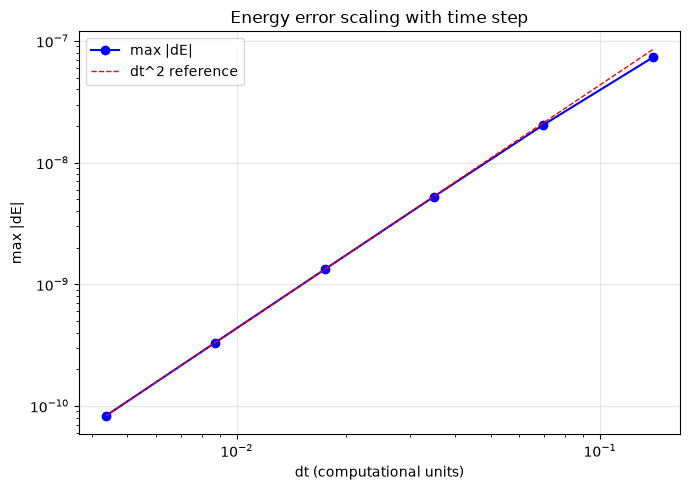

In [5]:
# ============================================================
# FIGURE 4: max|dE| vs dt (CONVERGENCE)
# ============================================================
fig, ax = plt.subplots(figsize=(7, 5))

dt_vals = []
dE_max_vals = []
for spo in steps_per_orbit_list:
    r = results[spo]
    sl = slice(2, -2)
    dt_vals.append(r['dt'])
    dE_max_vals.append(np.max(np.abs(r['E'][sl] - r['E'][2])))

dt_vals = np.array(dt_vals)
dE_max_vals = np.array(dE_max_vals)

ax.loglog(dt_vals, dE_max_vals, 'bo-', ms=6, label='max |dE|')

ref = dE_max_vals[-1] * (dt_vals / dt_vals[-1])**2
ax.loglog(dt_vals, ref, 'r--', lw=1, label='dt^2 reference')

ax.set_xlabel('dt (computational units)')
ax.set_ylabel('max |dE|')
ax.set_title('Energy error scaling with time step')
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('fig_1a_convergence.png', dpi=150, bbox_inches='tight')
plt.show()

## 2. Time reversibility

I integrate 50 orbits forward, reverse the run by swapping the last two saved positions (an exact reversal for Verlet, with no velocity estimate needed), and integrate 50 orbits back. The distance between the planet's final and starting positions measures how reversible the method is, for the same six step sizes.

In [6]:
# ============================================================
# PART (b): TIME REVERSIBILITY
# ============================================================

def grav_sim_verlet_reverse(mass, pos_last, pos_second_to_last, dt, num_steps):
    """
    Reverse the Verlet trajectory by swapping the last two positions.
    No velocity estimation is needed — this uses Verlet's time symmetry.
    """
    positions = np.zeros([mass.size, 3, num_steps+1])
    positions[:,:,0] = pos_last
    position = pos_second_to_last.copy()
    position_old = pos_last.copy()
    positions[:,:,1] = position
    for t in range(2, num_steps+1):
        acceleration = accel_grav(mass, position)
        position_new = verlet_step(position, position_old, acceleration, dt)
        position_old = position
        position = position_new
        positions[:,:,t] = position
    return positions

num_orbits = 50
tot_time = num_orbits * 2.0 * np.pi
steps_per_orbit_list = [45, 90, 180, 360, 720, 1440]

deviations = []

for spo in steps_per_orbit_list:
    dt = 2.0 * np.pi / spo
    num_steps = int(np.ceil(tot_time / dt))
    
    # Forward
    pos_fwd = grav_sim(mass, initial_position, initial_velocity, G*dt, num_steps)
    
    # Reverse: swap last two positions (no velocity needed)
    pos_bwd = grav_sim_verlet_reverse(mass, pos_fwd[:,:,-1].copy(),
                                       pos_fwd[:,:,-2].copy(), G*dt, num_steps)
    
    # Deviation of smaller mass
    dr = pos_bwd[1,:,-1] - initial_position[1,:]
    deviation = np.sqrt(np.sum(dr**2))
    deviations.append(deviation)
    
    print(f"spo={spo:5d}  dt={dt:.6f}  deviation={deviation:.6e} AU")

deviations = np.array(deviations)
dt_vals = np.array([2.0*np.pi/spo for spo in steps_per_orbit_list])

spo=   45  dt=0.139626  deviation=5.280970e-12 AU
spo=   90  dt=0.069813  deviation=1.046605e-11 AU
spo=  180  dt=0.034907  deviation=2.748545e-11 AU
spo=  360  dt=0.017453  deviation=1.628287e-11 AU
spo=  720  dt=0.008727  deviation=2.468122e-10 AU
spo= 1440  dt=0.004363  deviation=1.788390e-11 AU


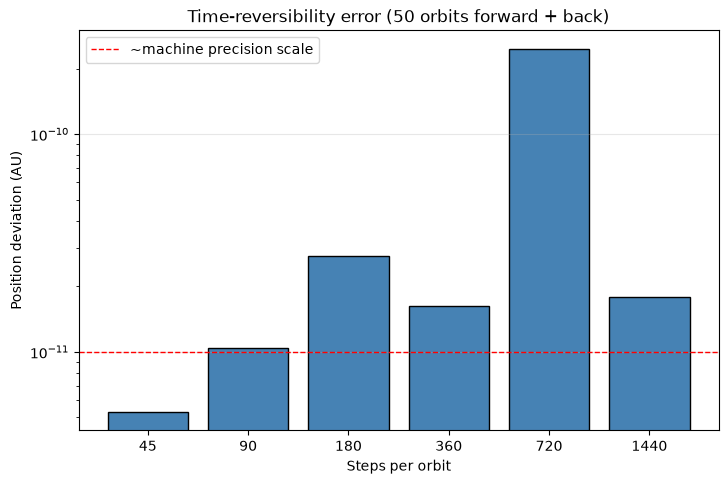

In [7]:
fig, ax = plt.subplots(figsize=(8, 5))

labels = [str(s) for s in steps_per_orbit_list]
ax.bar(labels, deviations, color='steelblue', edgecolor='black')
ax.set_yscale('log')
ax.set_xlabel('Steps per orbit')
ax.set_ylabel('Position deviation (AU)')
ax.set_title(f'Time-reversibility error ({num_orbits} orbits forward + back)')
ax.grid(True, alpha=0.3, axis='y')

# Add a horizontal reference line for machine epsilon scale
ax.axhline(y=1e-11, color='red', ls='--', lw=1, label='~machine precision scale')
ax.legend()

plt.subplots_adjust(left=0.15, right=0.95, top=0.92, bottom=0.12)
plt.savefig('fig_1b_deviation.png', dpi=150, bbox_inches='tight')
plt.show()

## 3. The Solar System from JPL Horizons

Positions and velocities for the Sun, eight planets, the Moon, and Pluto come from the JPL Horizons API (Solar System barycenter, ecliptic frame), converted to computational units. I integrate for 38.3 years and track how far the Sun moves from its starting position.

In [8]:
# ============================================================
# INITIAL CONDITIONS FROM JPL HORIZONS via API https://ssd-api.jpl.nasa.gov/doc/horizons.html
# ============================================================


import requests
import re
import numpy as np
 
def fetch_horizons_vectors(body_id, date_str, center='@0', units='AU-D'):
    url = 'https://ssd.jpl.nasa.gov/api/horizons.api'
    params = {
        'format':     'text',
        'COMMAND':    f"'{body_id}'",
        'OBJ_DATA':   'NO',
        'MAKE_EPHEM': 'YES',
        'EPHEM_TYPE': 'VECTORS',
        'CENTER':     f"'{center}'",
        'START_TIME':  f"'{date_str}'",
        'STOP_TIME':   f"'{date_str} 00:01'",
        'STEP_SIZE':  "'1 d'",
        'OUT_UNITS':   f"'{units}'",
        'VEC_TABLE':  "'2'",
        'VEC_LABELS': "'YES'",
        'CSV_FORMAT': "'NO'",
        'REF_PLANE':  "'ECLIPTIC'",
    }
    r = requests.get(url, params=params)
    text = r.text
    soe = text.index('$$SOE') + len('$$SOE')
    eoe = text.index('$$EOE')
    data_block = text[soe:eoe].strip()
    pairs = re.findall(r'([A-Z]+)\s*=\s*([+\-]?\d+\.\d+E[+\-]?\d+)', data_block)
    result = {k: float(v) for k, v in pairs}
    return {
        'x':  result['X'],  'y':  result['Y'],  'z':  result['Z'],
        'vx': result['VX'], 'vy': result['VY'], 'vz': result['VZ']
    }
 
# Bodies and their Horizons IDs
bodies = {
    'Sun':     '10',
    'Mercury': '199',
    'Venus':   '299',
    'Earth':   '399',
    'Moon':    '301',
    'Mars':    '499',
    'Jupiter': '599',
    'Saturn':  '699',
    'Uranus':  '799',
    'Neptune': '899',
    'Pluto':   '999',
}
 
# Masses in solar masses
masses_solar = {
    'Sun':     1.0,
    'Mercury': 1.6601e-7,
    'Venus':   2.4478e-6,
    'Earth':   3.0035e-6,
    'Moon':    3.6943e-8,
    'Mars':    3.2271e-7,
    'Jupiter': 9.5479e-4,
    'Saturn':  2.8588e-4,
    'Uranus':  4.3662e-5,
    'Neptune': 5.1514e-5,
    'Pluto':   7.396e-9,
}
 
date = '1988-06-07'   
 
print(f"Fetching SSB vectors for {date}...\n")
 
solar_system = {}
for name, bid in bodies.items():
    data = fetch_horizons_vectors(bid, date, center='@0', units='AU-D')
    solar_system[name] = data
    print(f"{name:10s}  x={data['x']:+15.9f}  y={data['y']:+15.9f}  z={data['z']:+15.9f}")
 
# Convert to computational units
# Horizons: AU and AU/day
# Code units: AU, solar masses, time = yr/(2*pi), G = 1
# Conversion: v_comp = v_AU_per_day * 365.25/(2*pi)
day_to_comp = 365.25 / (2.0 * np.pi)
 
body_names = list(bodies.keys())
N_bodies = len(body_names)
 
mass = np.array([masses_solar[name] for name in body_names])
initial_position = np.zeros([N_bodies, 3])
initial_velocity = np.zeros([N_bodies, 3])
 
for i, name in enumerate(body_names):
    d = solar_system[name]
    initial_position[i, :] = [d['x'], d['y'], d['z']]
    initial_velocity[i, :] = [d['vx'] * day_to_comp,
                               d['vy'] * day_to_comp,
                               d['vz'] * day_to_comp]
 
# Subtract COM velocity (should already be ~0 from SSB, but just in case)
total_mass = np.sum(mass)
com_vel = np.sum(mass[:, np.newaxis] * initial_velocity, axis=0) / total_mass
initial_velocity -= com_vel[np.newaxis, :]
 
print(f"\nLoaded {N_bodies} bodies. Ready to simulate.")
print(f"Velocity conversion factor: {day_to_comp:.4f} (AU/day -> comp units)")
 

Fetching SSB vectors for 1988-06-07...

Sun         x=   -0.003474746  y=   +0.001830045  z=   +0.000013038
Mercury     x=   -0.195233644  y=   -0.420561418  z=   -0.016878957
Venus       x=   -0.217507262  y=   -0.691734057  z=   +0.002913082
Earth       x=   -0.238149060  y=   -0.985597572  z=   -0.000012112
Moon        x=   -0.235783329  y=   -0.986314838  z=   -0.000034314
Mars        x=   +0.579348007  y=   -1.283520035  z=   -0.041247806
Jupiter     x=   +3.457357128  y=   +3.586833509  z=   -0.092331392
Saturn      x=   -0.176995556  y=  -10.038704079  z=   +0.182044816
Uranus      x=   -0.320086319  y=  -19.272903477  z=   -0.067419293
Neptune     x=   +4.635507566  y=  -29.860793856  z=   +0.508060611
Pluto       x=  -21.320437273  y=  -18.931661742  z=   +8.192831673

Loaded 11 bodies. Ready to simulate.
Velocity conversion factor: 58.1313 (AU/day -> comp units)


Integrating 38.3 years (27576 steps, dt=0.008727)...
Done!


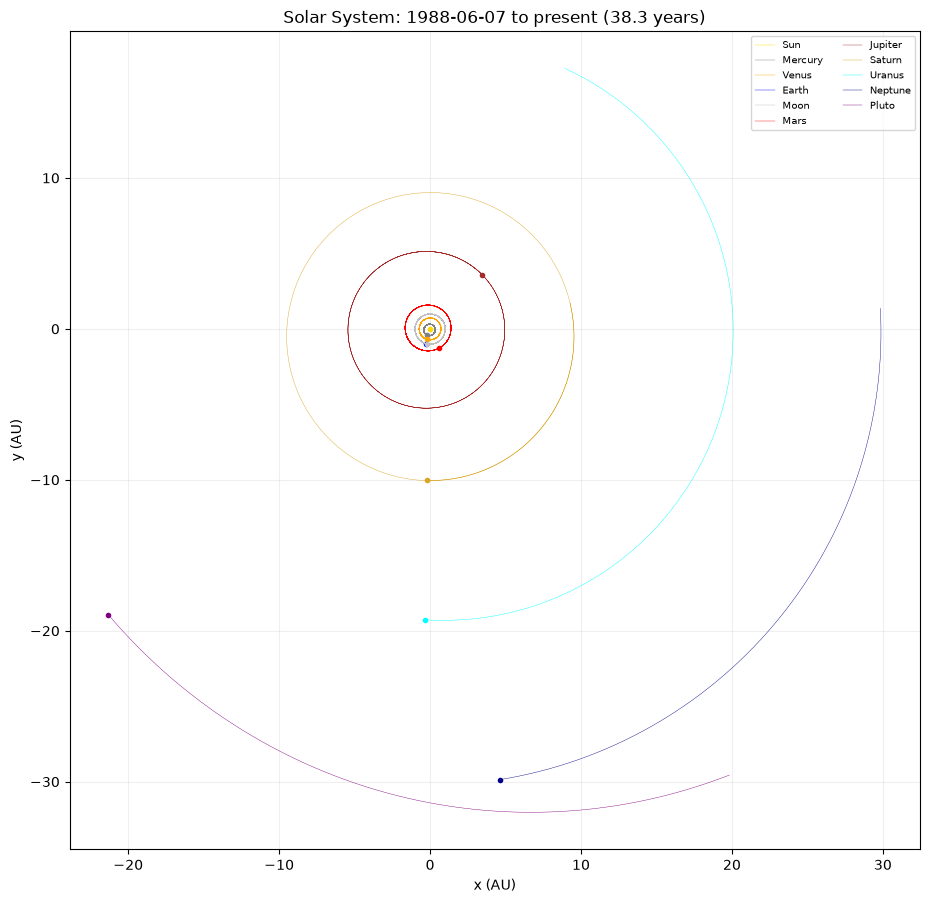

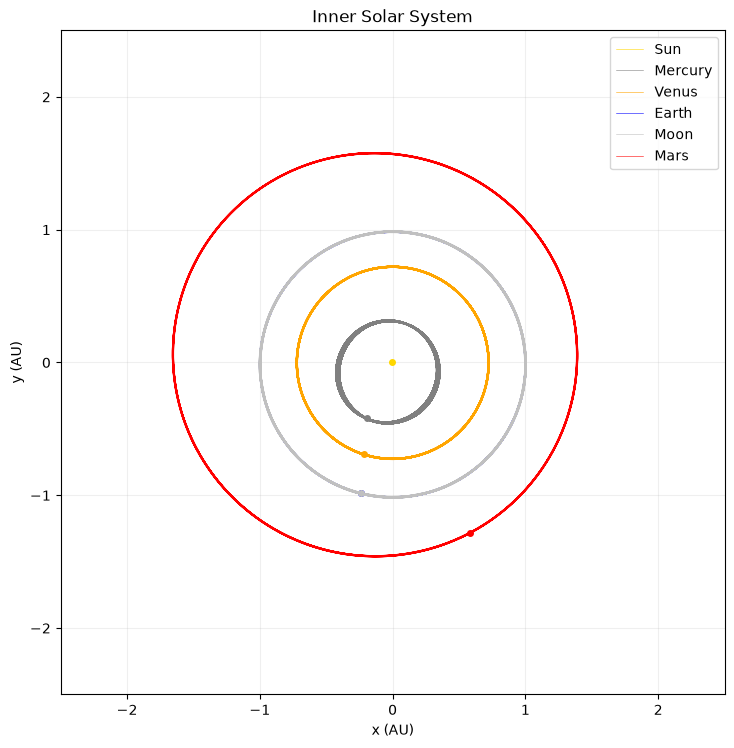

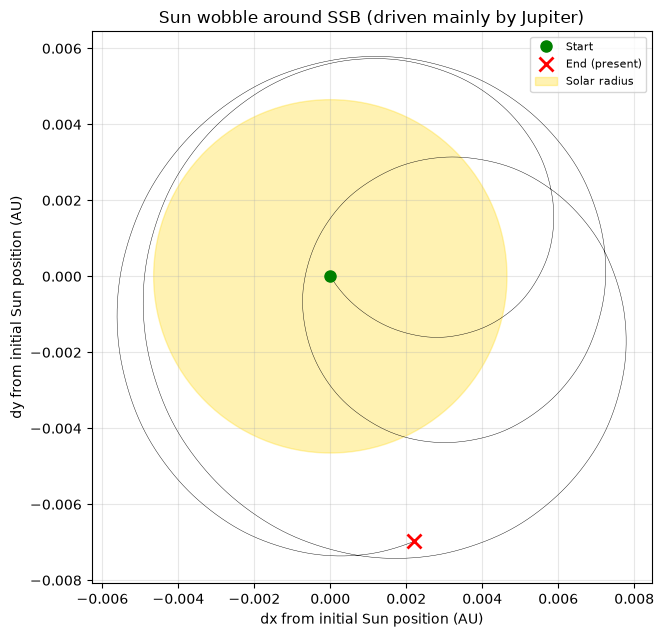

Max Sun displacement from initial position: 0.008333 AU
Solar radius: 0.00465 AU
Wobble / R_sun: 1.79


In [9]:
# ============================================================
# SIMULATE AND PLOT
# ============================================================
 
import matplotlib.pyplot as plt
 
G = 1.0
 
# Integration parameters
# From 1988-06-07 to ~2026-10-31 
years_to_integrate = 38.3
tot_time = years_to_integrate * 2.0 * np.pi
 
# Use 720 steps per Earth year (= 720 steps per 2*pi comp time)
steps_per_year = 720
dt = 2.0 * np.pi / steps_per_year
num_steps = int(np.ceil(tot_time / dt))
 
print(f"Integrating {years_to_integrate} years ({num_steps} steps, dt={dt:.6f})...")
positions = grav_sim(mass, initial_position, initial_velocity, G*dt, num_steps)
print("Done!")
 
# Time array in years
t_years = np.linspace(0, tot_time, num_steps + 1) / (2.0 * np.pi)
 
# ============================================================
# PLOT 1: FULL SOLAR SYSTEM (top-down view)
# ============================================================
 
colors = {
    'Sun': 'gold', 'Mercury': 'gray', 'Venus': 'orange',
    'Earth': 'blue', 'Moon': 'silver', 'Mars': 'red',
    'Jupiter': 'brown', 'Saturn': 'goldenrod',
    'Uranus': 'cyan', 'Neptune': 'darkblue', 'Pluto': 'purple'
}
 
fig, ax = plt.subplots(figsize=(10, 10))
for i, name in enumerate(body_names):
    ax.plot(positions[i, 0, :], positions[i, 1, :], '-',
            lw=0.3, color=colors[name], label=name)
    ax.plot(positions[i, 0, 0], positions[i, 1, 0], 'o',
            ms=3, color=colors[name])
 
ax.set_xlabel('x (AU)')
ax.set_ylabel('y (AU)')
ax.set_title(f'Solar System: {date} to present ({years_to_integrate:.1f} years)')
ax.set_aspect('equal')
ax.legend(fontsize=7, ncol=2, loc='upper right')
ax.grid(True, alpha=0.2)
plt.subplots_adjust(left=0.1, right=0.95, top=0.93, bottom=0.08)
plt.savefig('fig_1c_full_system.png', dpi=150, bbox_inches='tight')
plt.show()
 
# ============================================================
# PLOT 2: INNER SOLAR SYSTEM ZOOM
# ============================================================
 
fig, ax = plt.subplots(figsize=(8, 8))
inner = ['Sun', 'Mercury', 'Venus', 'Earth', 'Moon', 'Mars']
for i, name in enumerate(body_names):
    if name in inner:
        ax.plot(positions[i, 0, :], positions[i, 1, :], '-',
                lw=0.4, color=colors[name], label=name)
        ax.plot(positions[i, 0, 0], positions[i, 1, 0], 'o',
                ms=4, color=colors[name])
 
ax.set_xlim(-2.5, 2.5)
ax.set_ylim(-2.5, 2.5)
ax.set_xlabel('x (AU)')
ax.set_ylabel('y (AU)')
ax.set_title('Inner Solar System')
ax.set_aspect('equal')
ax.legend()
ax.grid(True, alpha=0.2)
plt.subplots_adjust(left=0.12, right=0.95, top=0.93, bottom=0.08)
plt.savefig('fig_1c_inner.png', dpi=150, bbox_inches='tight')
plt.show()
 
# ============================================================
# PLOT 3: SUN WOBBLE
# ============================================================
# The Sun is not at the origin -- it orbits the SSB!
# Plot Sun's path relative to its initial position
# Compare to the Sun's radius: R_sun = 0.00465 AU
 
R_sun_AU = 0.00465  # solar radius in AU
 
sun_idx = body_names.index('Sun')
sun_x = positions[sun_idx, 0, :] - positions[sun_idx, 0, 0]
sun_y = positions[sun_idx, 1, :] - positions[sun_idx, 1, 0]
 
fig, ax = plt.subplots(figsize=(7, 7))
ax.plot(sun_x, sun_y, 'k-', lw=0.3)
ax.plot(sun_x[0], sun_y[0], 'go', ms=8, label='Start')
ax.plot(sun_x[-1], sun_y[-1], 'rx', ms=10, mew=2, label='End (present)')
 
# Draw circle for Sun's radius
circle = plt.Circle((0, 0), R_sun_AU, color='gold', alpha=0.3, label='Solar radius')
ax.add_patch(circle)
 
ax.set_xlabel('dx from initial Sun position (AU)')
ax.set_ylabel('dy from initial Sun position (AU)')
ax.set_title('Sun wobble around SSB (driven mainly by Jupiter)')
ax.set_aspect('equal')
ax.legend(fontsize=8)
ax.grid(True, alpha=0.3)
plt.subplots_adjust(left=0.15, right=0.95, top=0.92, bottom=0.1)
plt.savefig('fig_1c_sun_wobble.png', dpi=150, bbox_inches='tight')
plt.show()
 
max_wobble = np.max(np.sqrt(sun_x**2 + sun_y**2))
print(f"Max Sun displacement from initial position: {max_wobble:.6f} AU")
print(f"Solar radius: {R_sun_AU} AU")
print(f"Wobble / R_sun: {max_wobble/R_sun_AU:.2f}")
 

## 4. Mercury's perihelion precession

A two-body Newtonian orbit shouldn't precess, so I first run the Sun and Mercury alone at four step sizes to measure how much drift the integrator itself adds (the numerical floor). Then I add a Jupiter with 10× its real mass, and separately a GR-style correction to gravity,

$$\frac{F}{m} = -\frac{GM}{r^2}\left(1 + \frac{\alpha}{r^2}\right).$$

Perihelion angles are measured relative to the Sun. For the GR case, perturbation theory predicts an advance of $\Delta\phi = 2\pi\alpha/p^2$ radians per orbit, where $p = a(1 - e^2)$, which I compare with the floor-subtracted measurement. The real relativistic value corresponds to $\alpha = 3GMp/c^2 \approx 1.1\times10^{-8}$ (about 43″ per century); I use $\alpha = 10^{-4}$ so the effect is visible within 2000 orbits.

=== 1. Numerical floor: Sun + Mercury, alpha = 0 ===
Steps/orbit | Drift (deg/orbit) | Rate (arcsec/century) | Ratio to prev
------------------------------------------------------------------------
        180 |       -1.2598e-01 |             -188303.6 |             -
        360 |       -3.1528e-02 |              -47126.8 |         4.00x
        720 |       -7.8841e-03 |              -11784.9 |         4.00x
       1440 |       -1.9712e-03 |               -2946.4 |         4.00x
Mean ratio per halving of dt: 4.00  ->  drift ~ dt^2.00

Sim 2: Sun + Mercury + Jupiter (mass x10), 2000 orbits...
Sim 3: Sun + Mercury + GR correction (alpha = 0.0001), 2000 orbits...

=== 2. Precession rates at 360 steps/orbit, 2000 orbits ===
Configuration                      |    deg/orbit |  arcsec/century
--------------------------------------------------------------------
Sun + Mercury (numerical floor)    |  -3.1528e-02 |        -47126.8
+ Jupiter x10 (raw)                |  -3.0111e-02 |        -450

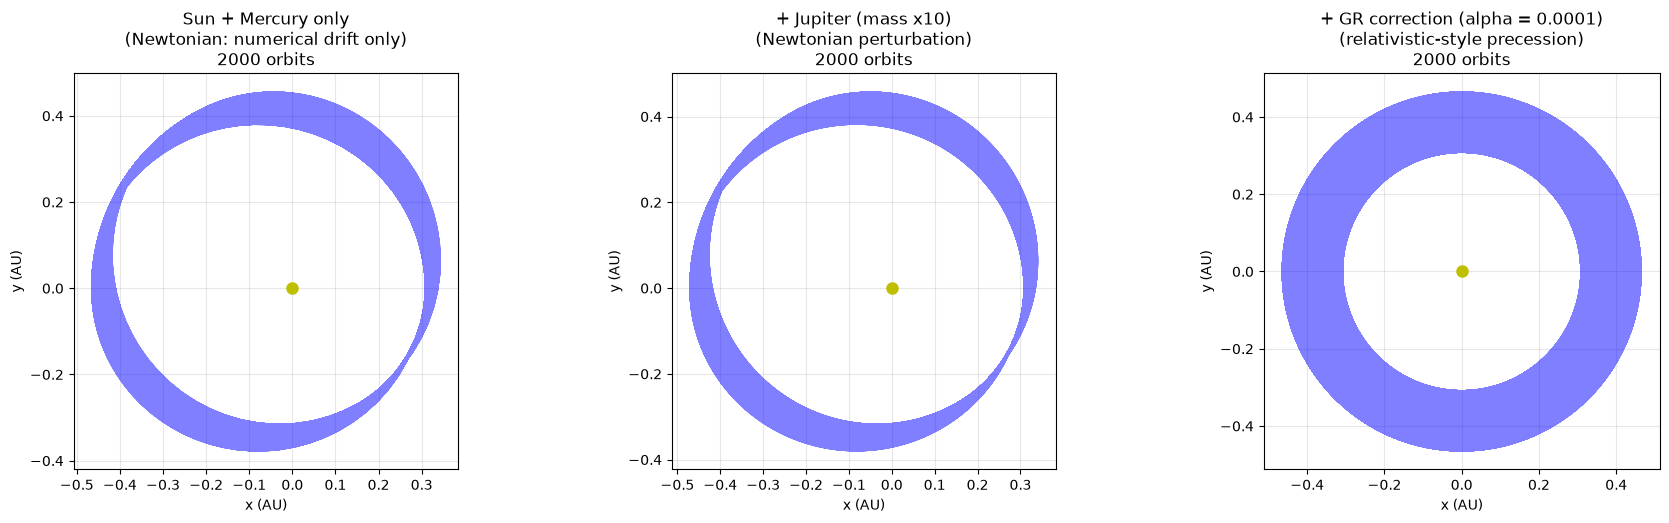

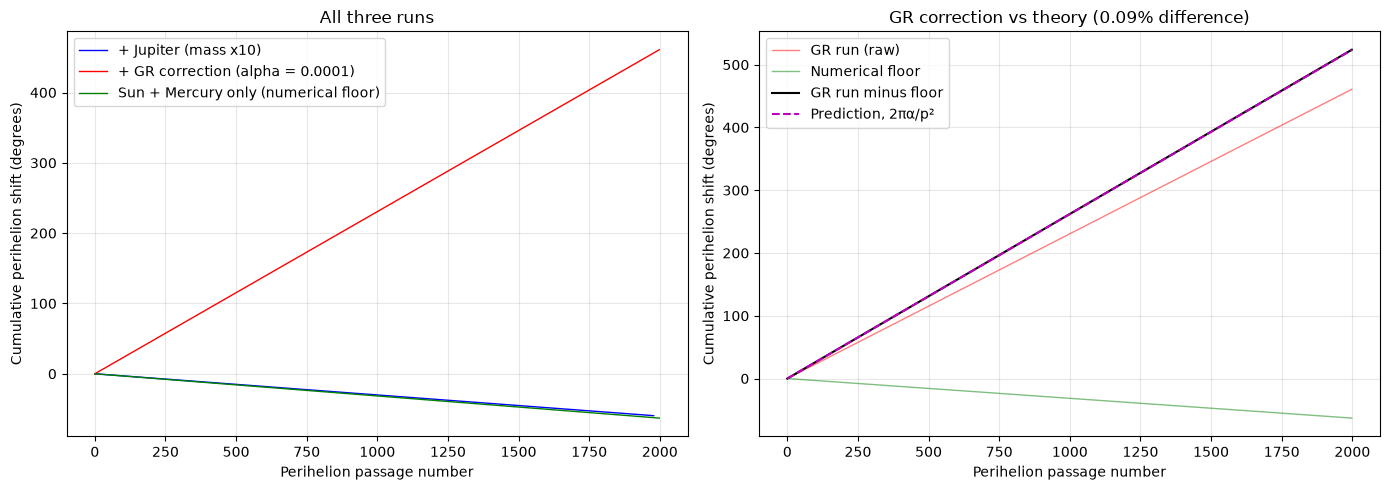

In [10]:
import numpy as np
import matplotlib.pyplot as plt

# ============================================================
# MERCURY'S PERIHELION PRECESSION
# Force law: F/m = -GM/r^2 * (1 + alpha/r^2)
#   alpha = 0  -> pure Newtonian gravity
#   alpha > 0  -> GR-style correction
# Weak-field GR gives delta_a = -3*GM*L^2/(c^2 r^4). With L^2 = GM*p,
# that is alpha = 3*GM*p/c^2, and the perihelion advances by
#   delta_phi = 6*pi*GM/(c^2*p) = 2*pi*alpha/p^2  radians per orbit.
# ============================================================

def accel_grav_GR(mass, position, alpha=0.0):
    """Pairwise gravitational acceleration with an optional (1 + alpha/r^2) factor."""
    N = mass.shape[0]
    accel = np.zeros([N, 3])
    for i in range(N - 1):
        for j in range(i + 1, N):
            displacement = position[j, :] - position[i, :]
            r_squared = displacement[0]**2 + displacement[1]**2 + displacement[2]**2
            r_cubed = r_squared * np.sqrt(r_squared)
            disp_over_r3 = displacement / r_cubed * (1.0 + alpha / r_squared)
            accel[i, :] += mass[j] * disp_over_r3
            accel[j, :] -= mass[i] * disp_over_r3
    return accel

def grav_sim_GR(mass, initial_position, initial_velocity, dt, num_steps, alpha=0.0):
    """Position-Verlet integration using accel_grav_GR."""
    positions = np.zeros([mass.size, 3, num_steps + 1])
    positions[:, :, 0] = initial_position
    acceleration = accel_grav_GR(mass, initial_position, alpha)
    position = first_step(initial_position, initial_velocity, acceleration, dt)
    position_old = initial_position
    positions[:, :, 1] = position
    for t in range(2, num_steps + 1):
        acceleration = accel_grav_GR(mass, position, alpha)
        position_new = verlet_step(position, position_old, acceleration, dt)
        position_old = position
        position = position_new
        positions[:, :, t] = position
    return positions

# ============================================================
# PERIHELION DETECTION
# ============================================================

def find_perihelion_angles(positions_planet):
    """
    Perihelion angle (degrees) at each passage.

    Each passage is found as a local minimum in r, then refined with a
    3-point parabola so the angle isn't limited to the time-step grid.
    The continuous (unwrapped) orbital angle is only used locally for that
    interpolation; each refined angle is then wrapped back to (-180, 180]
    and the list of perihelion angles is unwrapped on its own. Without that
    last step every orbit would add a full 360 degrees to the result.
    """
    x = positions_planet[0, :]
    y = positions_planet[1, :]
    r = np.sqrt(x**2 + y**2)
    theta = np.unwrap(np.arctan2(y, x))

    peri = []
    for i in range(2, len(r) - 2):
        if r[i] < r[i-1] and r[i] < r[i+1] and r[i] < r[i-2] and r[i] < r[i+2]:
            denom = 2.0 * (r[i-1] - 2.0 * r[i] + r[i+1])
            delta = (r[i-1] - r[i+1]) / denom if denom != 0 else 0.0
            if delta >= 0:
                peri.append(theta[i] + delta * (theta[i+1] - theta[i]))
            else:
                peri.append(theta[i] + delta * (theta[i] - theta[i-1]))

    peri = np.array(peri)
    wrapped = np.mod(peri + np.pi, 2.0 * np.pi) - np.pi
    return np.degrees(np.unwrap(wrapped))

def precession_rate(angles_deg, T_orb):
    """Least-squares slope of perihelion angle vs passage number.
    Returns (degrees per orbit, arcsec per century)."""
    orbits = np.arange(len(angles_deg))
    deg_per_orbit, _ = np.polyfit(orbits, angles_deg, 1)
    orbits_per_century = 100.0 / (T_orb / (2.0 * np.pi))
    return deg_per_orbit, deg_per_orbit * 3600.0 * orbits_per_century

# ============================================================
# ORBITAL PARAMETERS
# ============================================================
G = 1.0
m_sun = 1.0
m_mercury = 1.6601e-7
m_jupiter = 9.5479e-4

a_merc = 0.387098
e_merc = 0.205630
p_merc = a_merc * (1.0 - e_merc**2)          # semi-latus rectum
r_peri = a_merc * (1.0 - e_merc)
M_sm = m_sun + m_mercury
v_peri = np.sqrt(G * M_sm * (2.0 / r_peri - 1.0 / a_merc))
T_merc = 2.0 * np.pi * np.sqrt(a_merc**3 / (G * M_sm))
orbits_per_century = 100.0 / (T_merc / (2.0 * np.pi))

a_jup = 5.2026
e_jup = 0.0489
r_peri_jup = a_jup * (1.0 - e_jup)
M_sj = m_sun + m_jupiter
v_peri_jup = np.sqrt(G * M_sj * (2.0 / r_peri_jup - 1.0 / a_jup))

steps_per_orbit = 360          # baseline resolution for Sims 1-3
n_orbits = 2000                # same length for all three sims
dt = T_merc / steps_per_orbit

# Sun + Mercury, Mercury starting at perihelion on the +x axis
mass_ms = np.array([m_sun, m_mercury])
init_pos_ms = np.zeros([2, 3])
init_pos_ms[1, :] = [r_peri, 0, 0]
init_vel_ms = np.zeros([2, 3])
init_vel_ms[1, :] = [0, v_peri, 0]
init_vel_ms[0, :] = -m_mercury / m_sun * init_vel_ms[1, :]

# ============================================================
# SIM 1: NUMERICAL FLOOR (Sun + Mercury, alpha = 0) AT FOUR STEP SIZES
# A two-body Newtonian orbit shouldn't precess at all, so any drift
# here is integrator error. Verlet should make it shrink as dt^2.
# ============================================================
spo_list = [180, 360, 720, 1440]
floor = {}

print("=== 1. Numerical floor: Sun + Mercury, alpha = 0 ===")
print(f"{'Steps/orbit':>11s} | {'Drift (deg/orbit)':>17s} | {'Rate (arcsec/century)':>21s} | {'Ratio to prev':>13s}")
print("-" * 72)
prev = None
for spo in spo_list:
    pos = grav_sim_GR(mass_ms, init_pos_ms, init_vel_ms, G * T_merc / spo,
                      n_orbits * spo, alpha=0.0)
    ang = find_perihelion_angles(pos[1, :, :] - pos[0, :, :])
    deg_orb, rate = precession_rate(ang, T_merc)
    floor[spo] = {'angles': ang, 'deg_per_orbit': deg_orb, 'rate': rate}
    if spo == steps_per_orbit:
        pos_ms = pos                      # keep the baseline run for plotting
    ratio = f"{prev / deg_orb:.2f}x" if prev is not None else "-"
    print(f"{spo:11d} | {deg_orb:+17.4e} | {rate:+21.1f} | {ratio:>13s}")
    prev = deg_orb
    del pos

ratios = [floor[spo_list[k-1]]['deg_per_orbit'] / floor[spo_list[k]]['deg_per_orbit']
          for k in range(1, len(spo_list))]
order = np.log2(np.mean(ratios))
print(f"Mean ratio per halving of dt: {np.mean(ratios):.2f}  ->  drift ~ dt^{order:.2f}\n")

angles_ms = floor[steps_per_orbit]['angles']
floor_deg_orb = floor[steps_per_orbit]['deg_per_orbit']
floor_rate = floor[steps_per_orbit]['rate']

# ============================================================
# SIM 2: + JUPITER (mass x10), Newtonian
# ============================================================
jupiter_enhance = 10.0
mass_msj = np.array([m_sun, m_mercury, m_jupiter * jupiter_enhance])
init_pos_msj = np.zeros([3, 3])
init_pos_msj[1, :] = [r_peri, 0, 0]
init_pos_msj[2, :] = [r_peri_jup, 0, 0]
init_vel_msj = np.zeros([3, 3])
init_vel_msj[1, :] = [0, v_peri, 0]
init_vel_msj[2, :] = [0, v_peri_jup, 0]
init_vel_msj[0, :] = -(m_mercury * init_vel_msj[1, :]
                       + m_jupiter * jupiter_enhance * init_vel_msj[2, :]) / m_sun

num_steps_main = n_orbits * steps_per_orbit
print(f"Sim 2: Sun + Mercury + Jupiter (mass x{jupiter_enhance:.0f}), {n_orbits} orbits...")
pos_msj = grav_sim_GR(mass_msj, init_pos_msj, init_vel_msj, G * dt, num_steps_main, alpha=0.0)
angles_msj = find_perihelion_angles(pos_msj[1, :, :] - pos_msj[0, :, :])   # relative to the Sun
deg_orb_msj, rate_msj = precession_rate(angles_msj, T_merc)

# ============================================================
# SIM 3: + GR-STYLE CORRECTION (alpha enhanced so it shows up in 2000 orbits)
# ============================================================
alpha_enhanced = 1e-4
print(f"Sim 3: Sun + Mercury + GR correction (alpha = {alpha_enhanced}), {n_orbits} orbits...\n")
pos_gr = grav_sim_GR(mass_ms, init_pos_ms, init_vel_ms, G * dt, num_steps_main, alpha=alpha_enhanced)
angles_gr = find_perihelion_angles(pos_gr[1, :, :] - pos_gr[0, :, :])
deg_orb_gr_raw, rate_gr_raw = precession_rate(angles_gr, T_merc)

# ============================================================
# FLOOR SUBTRACTION AND COMPARISON WITH 2*pi*alpha/p^2
# ============================================================
pred_deg_orb = np.degrees(2.0 * np.pi * alpha_enhanced / p_merc**2)
pred_rate = pred_deg_orb * 3600.0 * orbits_per_century
meas_deg_orb = deg_orb_gr_raw - floor_deg_orb
meas_rate = rate_gr_raw - floor_rate
pct_diff = abs(meas_deg_orb - pred_deg_orb) / pred_deg_orb * 100.0

print("=== 2. Precession rates at 360 steps/orbit, 2000 orbits ===")
print(f"{'Configuration':<34s} | {'deg/orbit':>12s} | {'arcsec/century':>15s}")
print("-" * 68)
print(f"{'Sun + Mercury (numerical floor)':<34s} | {floor_deg_orb:+12.4e} | {floor_rate:+15.1f}")
print(f"{'+ Jupiter x10 (raw)':<34s} | {deg_orb_msj:+12.4e} | {rate_msj:+15.1f}")
print(f"{'+ Jupiter x10 (floor subtracted)':<34s} | {deg_orb_msj - floor_deg_orb:+12.4e} | {rate_msj - floor_rate:+15.1f}")
print(f"{'+ GR alpha=1e-4 (raw)':<34s} | {deg_orb_gr_raw:+12.4e} | {rate_gr_raw:+15.1f}")
print(f"{'+ GR alpha=1e-4 (floor subtracted)':<34s} | {meas_deg_orb:+12.4e} | {meas_rate:+15.1f}")
print(f"{'Predicted, 2*pi*alpha/p^2':<34s} | {pred_deg_orb:+12.4e} | {pred_rate:+15.1f}")
print(f"\nFloor-subtracted GR vs prediction: {pct_diff:.3f}% difference")

# ============================================================
# OPTIONAL: REAL GR (alpha ~ 1.1e-8, about 43 arcsec/century)
# The real effect is ~10,000x smaller, so it needs a much finer time step.
# Slow in pure Python (~1.4 million steps per run, two runs), so off by default.
# ============================================================
RUN_REAL_GR = False

c_sim = 299792.458 / 29.7846918     # speed of light in code units (AU per yr/2pi)
alpha_real = 3.0 * G * M_sm * p_merc / c_sim**2
pred_real_rate = np.degrees(2.0 * np.pi * alpha_real / p_merc**2) * 3600.0 * orbits_per_century
print(f"\nReal GR: alpha = {alpha_real:.4e} -> predicted {pred_real_rate:.2f} arcsec/century")

if RUN_REAL_GR:
    spo_fine = 7200
    n_orbits_fine = 200
    dt_fine = T_merc / spo_fine
    steps_fine = n_orbits_fine * spo_fine
    pos = grav_sim_GR(mass_ms, init_pos_ms, init_vel_ms, G * dt_fine, steps_fine, alpha=0.0)
    _, floor_fine = precession_rate(find_perihelion_angles(pos[1, :, :] - pos[0, :, :]), T_merc)
    del pos
    pos = grav_sim_GR(mass_ms, init_pos_ms, init_vel_ms, G * dt_fine, steps_fine, alpha=alpha_real)
    _, raw_fine = precession_rate(find_perihelion_angles(pos[1, :, :] - pos[0, :, :]), T_merc)
    del pos
    print(f"  {spo_fine} steps/orbit, {n_orbits_fine} orbits: floor {floor_fine:+.2f}, "
          f"raw {raw_fine:+.2f}, net {raw_fine - floor_fine:+.2f} arcsec/century")

# ============================================================
# PLOT 1: MERCURY'S ORBIT IN THE THREE CASES
# ============================================================
fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))
panels = [
    (pos_ms[1] - pos_ms[0], 'Sun + Mercury only\n(Newtonian: numerical drift only)'),
    (pos_msj[1] - pos_msj[0], f'+ Jupiter (mass x{jupiter_enhance:.0f})\n(Newtonian perturbation)'),
    (pos_gr[1] - pos_gr[0], f'+ GR correction (alpha = {alpha_enhanced})\n(relativistic-style precession)'),
]
for ax, (xy, title) in zip(axes, panels):
    ax.plot(xy[0, ::5], xy[1, ::5], 'b-', lw=0.05, alpha=0.5)
    ax.plot(0, 0, 'yo', ms=8)
    ax.set_xlabel('x (AU)')
    ax.set_ylabel('y (AU)')
    ax.set_title(f'{title}\n{n_orbits} orbits')
    ax.set_aspect('equal')
    ax.grid(True, alpha=0.3)
plt.subplots_adjust(left=0.05, right=0.98, top=0.82, bottom=0.1, wspace=0.25)
plt.savefig('fig_G6_orbits.png', dpi=150, bbox_inches='tight')
plt.show()

# ============================================================
# PLOT 2: CUMULATIVE PERIHELION SHIFT
# Left: all three runs. Right: the GR run with the floor removed vs theory.
# ============================================================
n = np.arange(min(len(angles_ms), len(angles_gr)))
shift_ms = angles_ms[n] - angles_ms[0]
shift_gr = angles_gr[n] - angles_gr[0]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

ax1.plot(np.arange(len(angles_msj)), angles_msj - angles_msj[0], 'b-', lw=1,
         label=f'+ Jupiter (mass x{jupiter_enhance:.0f})')
ax1.plot(n, shift_gr, 'r-', lw=1, label=f'+ GR correction (alpha = {alpha_enhanced})')
ax1.plot(n, shift_ms, 'g-', lw=1, label='Sun + Mercury only (numerical floor)')
ax1.set_xlabel('Perihelion passage number')
ax1.set_ylabel('Cumulative perihelion shift (degrees)')
ax1.set_title('All three runs')
ax1.legend()
ax1.grid(True, alpha=0.3)

ax2.plot(n, shift_gr, 'r-', lw=1, alpha=0.5, label='GR run (raw)')
ax2.plot(n, shift_ms, 'g-', lw=1, alpha=0.5, label='Numerical floor')
ax2.plot(n, shift_gr - shift_ms, 'k-', lw=1.5, label='GR run minus floor')
ax2.plot(n, pred_deg_orb * n, 'm--', lw=1.5, label='Prediction, 2πα/p²')
ax2.set_xlabel('Perihelion passage number')
ax2.set_ylabel('Cumulative perihelion shift (degrees)')
ax2.set_title(f'GR correction vs theory ({pct_diff:.2f}% difference)')
ax2.legend()
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('fig_G6_precession.png', dpi=150, bbox_inches='tight')
plt.show()
